## Kütüphane Kurulumu

In [ ]:
# Gerekli kütüphanelerin kurulumu
!pip install -q zenodo_get kagglehub

import kagglehub
import shutil
import os
import zipfile

# ---------------------------------------------------------
# 1. ARI VERİ SETİ (KAGGLE)
# ---------------------------------------------------------
print("--- 1. Arı Veri Seti (Kaggle) Hazırlanıyor ---")
# kagglehub veriyi gizli cache klasörüne indirir
bee_cache_path = kagglehub.dataset_download("jenny18/honey-bee-annotated-images")
bee_target_path = "/content/bee_dataset"

# Cache'deki veriyi sizin görebileceğiniz /content/bee_dataset klasörüne kopyalıyoruz
if os.path.exists(bee_target_path):
    shutil.rmtree(bee_target_path) # Varsa eski klasörü sil
shutil.copytree(bee_cache_path, bee_target_path)

print(f"✅ Arı veri seti hazır!\nKlasör yolu: {bee_target_path}\n")

# ---------------------------------------------------------
# 2. VARROA PARAZİT VERİ SETİ (ZENODO)
# ---------------------------------------------------------
print("--- 2. Varroa Parazit Veri Seti (Zenodo) İndiriliyor ---")
varroa_target_path = "/content/varroa_dataset"
os.makedirs(varroa_target_path, exist_ok=True)

# zenodo_get ile indirme (Küçük -o parametresi ile)
!zenodo_get 4085044 -o {varroa_target_path}

print("\n--- Zip Dosyaları Çıkartılıyor ---")
for item in os.listdir(varroa_target_path):
    if item.endswith(".zip"):
        file_path = os.path.join(varroa_target_path, item)
        print(f"📦 {item} çıkartılıyor...")
        with zipfile.ZipFile(file_path, 'r') as zip_ref:
            # Zip içeriğini klasöre çıkar
            zip_ref.extractall(varroa_target_path)
        # Yer kaplamaması için zip dosyasını sil
        os.remove(file_path)

print(f"\n✅ Varroa veri seti başarıyla hazırlandı!")
print(f"Varroa Verisi Yolu: {varroa_target_path}")

--- 1. Arı Veri Seti (Kaggle) Hazırlanıyor ---
Using Colab cache for faster access to the 'honey-bee-annotated-images' dataset.
✅ Arı veri seti hazır!
Klasör yolu: /content/bee_dataset

--- 2. Varroa Parazit Veri Seti (Zenodo) İndiriliyor ---
INFO: Output directory: /content/varroa_dataset
INFO: Title: VarroaDataset
INFO: Total size: 1.2 GB
INFO: Number of files: 4
INFO: gt.csv is already downloaded correctly.
SUCCESS: All specified files have been processed.

--- Zip Dosyaları Çıkartılıyor ---
📦 train.zip çıkartılıyor...
📦 test.zip çıkartılıyor...
📦 val.zip çıkartılıyor...

✅ Varroa veri seti başarıyla hazırlandı!
Varroa Verisi Yolu: /content/varroa_dataset


## Veri Ön İşleme (Data Preprocessing)

In [ ]:
import pandas as pd
import os

print("--- 1. KAGGLE ARI VERİ SETİ ---")
bee_csv_path = "/content/bee_dataset/bee_data.csv"
bee_df = pd.read_csv(bee_csv_path)

print(f"Toplam Örnek Sayısı: {len(bee_df)}")
print(f"Sütun İsimleri: {list(bee_df.columns)}")
# Sınıf dağılımını görelim (Hastalık durumları)
if 'health' in bee_df.columns:
    print("\nSınıf Dağılımı (Health Sütunu):")
    print(bee_df['health'].value_counts())
else:
    print("Health sütunu bulunamadı, ilk 3 satır:")
    print(bee_df.head(3))


print("\n" + "="*40 + "\n")


print("--- 2. ZENODO VARROA VERİ SETİ ---")
varroa_csv_path = "/content/varroa_dataset/gt.csv"
varroa_df = pd.read_csv(varroa_csv_path)

print(f"Toplam Örnek Sayısı: {len(varroa_df)}")
print(f"Sütun İsimleri: {list(varroa_df.columns)}")
# İlk birkaç satırı görelim ki etiket formatını anlayalım
print("\nİlk 3 Satır:")
print(varroa_df.head(3))

--- 1. KAGGLE ARI VERİ SETİ ---
Toplam Örnek Sayısı: 5172
Sütun İsimleri: ['file', 'date', 'time', 'location', 'zip code', 'subspecies', 'health', 'pollen_carrying', 'caste']

Sınıf Dağılımı (Health Sütunu):
health
healthy                       3384
few varrao, hive beetles       579
Varroa, Small Hive Beetles     472
ant problems                   457
hive being robbed              251
missing queen                   29
Name: count, dtype: int64


--- 2. ZENODO VARROA VERİ SETİ ---
Toplam Örnek Sayısı: 13508
Sütun İsimleri: ['test/videos/2017-09-01_10-54-26/2017-09-01_10-54-26.mp4-bee_id_7741-15-1.png 1 84 143 109 172 54 142 82 172']

İlk 3 Satır:
  test/videos/2017-09-01_10-54-26/2017-09-01_10-54-26.mp4-bee_id_7741-15-1.png 1 84 143 109 172 54 142 82 172
0  test/videos/2017-09-01_10-54-26/2017-09-01_10-...                                                         
1  test/videos/2017-09-01_10-54-26/2017-09-01_10-...                                                         
2  test/video

In [ ]:
import os
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

print("--- Kaggle Arı Veri Seti (Data Augmentation ile) Hazırlanıyor ---")

# 1. SINIF ETİKETLERİNİ SAYISALLAŞTIRMA (0, 1, 2, 3, 4, 5)
label_encoder = LabelEncoder()
bee_df['label'] = label_encoder.fit_transform(bee_df['health'])
num_classes_bee = len(label_encoder.classes_)
print(f"Toplam Sınıf Sayısı: {num_classes_bee}")
print(f"Sınıf İsimleri: {label_encoder.classes_}")

# 2. VERİYİ EĞİTİM (%80) VE TEST (%20) OLARAK BÖLME
# stratify=bee_df['label'] parametresi, o azınlık olan 29 fotoğrafın hem eğitime hem teste dengeli dağılmasını sağlar!
train_df, test_df = train_test_split(bee_df, test_size=0.2, random_state=42, stratify=bee_df['label'])

# 3. GEOMETRİK ROTASYONLAR (DATA AUGMENTATION)
# Eğitim için (Döndürme, çevirme ve renk oyunları var - Ezberlemeyi önler)
train_transforms_bee = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Test için (Sadece boyutlandırma var, rotasyon ASLA yapılmaz)
test_transforms_bee = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 4. PYTORCH DATASET SINIFI (Kaggle klasör yapısına özel)
class BeeDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        # CSV'deki dosya isimlerini alıp klasör yoluyla birleştiriyoruz
        img_name = self.dataframe.iloc[idx]['file']

        # Kaggle veri setinde resimler klasörün içinde alt klasörlere (bee_imgs) dağılmış olabilir
        # Dosyayı bulmak için güvenli yol birleştirme yapıyoruz
        img_path = os.path.join(self.image_dir, "bee_imgs", img_name)

        image = Image.open(img_path).convert('RGB')
        label = self.dataframe.iloc[idx]['label']

        if self.transform:
            image = self.transform(image)

        return image, label

# 5. DATALOADER'LARI OLUŞTURMA
bee_image_dir = "/content/bee_dataset" # Kaggle verisinin ana klasörü

bee_train_dataset = BeeDataset(train_df, bee_image_dir, transform=train_transforms_bee)
bee_test_dataset = BeeDataset(test_df, bee_image_dir, transform=test_transforms_bee)

bee_train_loader = DataLoader(bee_train_dataset, batch_size=32, shuffle=True)
bee_test_loader = DataLoader(bee_test_dataset, batch_size=32, shuffle=False)

print("\n✅ Kaggle Arı Veri Seti DataLoader'ları başarıyla oluşturuldu!")
print(f"Eğitim Seti: {len(bee_train_dataset)} fotoğraf")
print(f"Test Seti: {len(bee_test_dataset)} fotoğraf")

--- Kaggle Arı Veri Seti (Data Augmentation ile) Hazırlanıyor ---
Toplam Sınıf Sayısı: 6
Sınıf İsimleri: ['Varroa, Small Hive Beetles' 'ant problems' 'few varrao, hive beetles'
 'healthy' 'hive being robbed' 'missing queen']

✅ Kaggle Arı Veri Seti DataLoader'ları başarıyla oluşturuldu!
Eğitim Seti: 4137 fotoğraf
Test Seti: 1035 fotoğraf


## Train-Test Oranları Hazırlama - Pipeline Kurulumu

In [ ]:
import os
import glob
import torch
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

print("--- AKADEMİK VERİ BORU HATTI KURULUYOR (Data Aug. & Stratify) ---")

# 1. Klasör Karmaşası Çözücü
all_image_paths = glob.glob("/content/bee_dataset/**/*.png", recursive=True)
image_dict = {os.path.basename(p): p for p in all_image_paths}

# 2. Etiketleri Sayısallaştırma
bee_csv_path = "/content/bee_dataset/bee_data.csv"
bee_df = pd.read_csv(bee_csv_path)

label_encoder = LabelEncoder()
bee_df['label'] = label_encoder.fit_transform(bee_df['health'])
num_classes_bee = len(label_encoder.classes_)

# 3. VERİ AYRIMI (En Önemli Kısım: Stratify)
# Sınıf dengesizliğini koruyarak (her sınıftan adil alarak) böler
# %80-20 Ayrımı (Bunu ana ayrım olarak kabul ediyoruz)
train_df_80, test_df_20 = train_test_split(bee_df, test_size=0.2, random_state=42, stratify=bee_df['label'])

# İsterseniz hocanızın tablosu için %70-30 ayrımı
train_df_70, test_df_30 = train_test_split(bee_df, test_size=0.3, random_state=42, stratify=bee_df['label'])

# 4. DATA AUGMENTATION (Jürinin İstediği Geometrik Rotasyonlar)
train_transforms_bee = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),         # Ezber kırmak için çevirme
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),          # Döndürme
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transforms_bee = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 5. DATASET SINIFI
class BeeDatasetSafe(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_name = self.dataframe.iloc[idx]['file']
        clean_name = os.path.basename(img_name)
        img_path = image_dict.get(clean_name)

        image = Image.open(img_path).convert('RGB')
        label = self.dataframe.iloc[idx]['label']

        if self.transform:
            image = self.transform(image)
        return image, label

# 6. DATALOADER'LARIN OLUŞTURULMASI
batch_size = 32

bee_train_data_80 = BeeDatasetSafe(train_df_80, transform=train_transforms_bee)
bee_test_data_20 = BeeDatasetSafe(test_df_20, transform=test_transforms_bee)

bee_train_loader_80 = DataLoader(bee_train_data_80, batch_size=batch_size, shuffle=True)
bee_test_loader_20 = DataLoader(bee_test_data_20, batch_size=batch_size, shuffle=False)

print(f"✅ Boru Hattı Hazır! (Dengeli Ayrım ve Rotasyonlar Aktif)")
print(f"Sınıf Sayısı: {num_classes_bee}")
print(f"%80 Eğitim Seti: {len(bee_train_data_80)} fotoğraf")
print(f"%20 Test Seti: {len(bee_test_data_20)} fotoğraf")

--- AKADEMİK VERİ BORU HATTI KURULUYOR (Data Aug. & Stratify) ---
✅ Boru Hattı Hazır! (Dengeli Ayrım ve Rotasyonlar Aktif)
Sınıf Sayısı: 6
%80 Eğitim Seti: 4137 fotoğraf
%20 Test Seti: 1035 fotoğraf


##Algoritma-1: SVM (Destek Vektör Makineleri) - PCA


In [ ]:
import numpy as np
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score
import time
from torch.utils.data import DataLoader

print("--- KAGGLE (ARI) SVM İÇİN TAM VERİ EĞİTİMİ (RAM SINIRI KALDIRILDI) ---")

# 1. Önce hocanızın tablosu için eksik olan %70-%30 DataLoader'larını oluşturalım
# (DataFramelerimiz önceki hücrede train_df_70 ve test_df_30 olarak hazırdı)
bee_train_data_70 = BeeDatasetSafe(train_df_70, transform=train_transforms_bee)
bee_test_data_30 = BeeDatasetSafe(test_df_30, transform=test_transforms_bee)

bee_train_loader_70 = DataLoader(bee_train_data_70, batch_size=32, shuffle=True)
bee_test_loader_30 = DataLoader(bee_test_data_30, batch_size=32, shuffle=False)

# 2. Sizin Düzleştirme (Flatten) Fonksiyonunuz (Sınırsız)
def extract_features(dataloader):
    features = []
    labels = []
    for imgs, lbls in dataloader:
        imgs_flat = imgs.view(imgs.shape[0], -1)
        features.append(imgs_flat.numpy())
        labels.append(lbls.numpy())
    return np.vstack(features), np.concatenate(labels)

# %70-30 Verilerini Çıkarma
print("%70-%30 verileri düzleştiriliyor (Tüm Veri)...")
X_train_70, y_train_70 = extract_features(bee_train_loader_70)
X_test_30, y_test_30 = extract_features(bee_test_loader_30)

# %80-20 Verilerini Çıkarma
print("%80-%20 verileri düzleştiriliyor (Tüm Veri)...")
X_train_80, y_train_80 = extract_features(bee_train_loader_80)
X_test_20, y_test_20 = extract_features(bee_test_loader_20)

print("\n--- Boyut İndirgeme (PCA) Uygulanıyor ---")
# İki farklı ayrım için iki ayrı PCA objesi kullanmak daha güvenlidir
pca_70 = PCA(n_components=100, random_state=42)
X_train_70_pca = pca_70.fit_transform(X_train_70)
X_test_30_pca = pca_70.transform(X_test_30)

pca_80 = PCA(n_components=100, random_state=42)
X_train_80_pca = pca_80.fit_transform(X_train_80)
X_test_20_pca = pca_80.transform(X_test_20)
print("PCA tamamlandı! Yeni boyut: 100")

# --- SVM EĞİTİMİ VE TESTİ ---
def train_and_evaluate_svm(X_train, y_train, X_test, y_test, split_name):
    print(f"\nModel Eğitiliyor: SVM ({split_name}) ...")
    start_time = time.time()

    svm_model = SVC(kernel='rbf', class_weight='balanced', random_state=42)
    svm_model.fit(X_train, y_train)

    preds = svm_model.predict(X_test)

    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average='macro')
    recall = recall_score(y_test, preds, average='macro')
    precision = precision_score(y_test, preds, average='macro', zero_division=0)

    end_time = time.time()
    print(f"Eğitim Süresi: {end_time - start_time:.2f} saniye")

    print(f"\n--- {split_name} SONUÇLARI ---")
    print(f"Accuracy : {acc:.4f}")
    print(f"F1 score : {f1:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"Precision: {precision:.4f}")

# Sonuçları Göster
train_and_evaluate_svm(X_train_70_pca, y_train_70, X_test_30_pca, y_test_30, split_name="%70 Eğitim - %30 Test")
print("-" * 40)
train_and_evaluate_svm(X_train_80_pca, y_train_80, X_test_20_pca, y_test_20, split_name="%80 Eğitim - %20 Test")

--- KAGGLE (ARI) SVM İÇİN TAM VERİ EĞİTİMİ (RAM SINIRI KALDIRILDI) ---
%70-%30 verileri düzleştiriliyor (Tüm Veri)...
%80-%20 verileri düzleştiriliyor (Tüm Veri)...

--- Boyut İndirgeme (PCA) Uygulanıyor ---
PCA tamamlandı! Yeni boyut: 100

Model Eğitiliyor: SVM (%70 Eğitim - %30 Test) ...
Eğitim Süresi: 2.13 saniye

--- %70 Eğitim - %30 Test SONUÇLARI ---
Accuracy : 0.7616
F1 score : 0.5927
Recall   : 0.6271
Precision: 0.6716
----------------------------------------

Model Eğitiliyor: SVM (%80 Eğitim - %20 Test) ...
Eğitim Süresi: 2.74 saniye

--- %80 Eğitim - %20 Test SONUÇLARI ---
Accuracy : 0.7971
F1 score : 0.6685
Recall   : 0.6952
Precision: 0.6907


##Algoritma-2 (ResNet-50)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import time
import gc
from torchvision import models
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

# 1. ÖZEL FONKSİYONLARIN TANIMLANMASI
class FocalLoss(nn.Module):
    def __init__(self, alpha=1.0, gamma=2.0, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = self.alpha * (1 - pt) ** self.gamma * ce_loss
        if self.reduction == 'mean': return focal_loss.mean()
        elif self.reduction == 'sum': return focal_loss.sum()
        return focal_loss

def mixup_data(x, y, alpha=0.2):
    if alpha > 0: lam = np.random.beta(alpha, alpha)
    else: lam = 1
    batch_size = x.size()[0]
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

# 2. İLERİ SEVİYE EĞİTİM DÖNGÜSÜ
def train_eval_bee_advanced(model, train_loader, test_loader, epochs=10):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)

    # Standart CrossEntropy yerine FOCAL LOSS!
    criterion = FocalLoss(alpha=1.0, gamma=2.0)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        run_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            # %50 ihtimalle MixUp uygula
            apply_mixup = np.random.rand() > 0.5
            optimizer.zero_grad()

            if apply_mixup:
                inputs_mixed, targets_a, targets_b, lam = mixup_data(inputs, labels, alpha=0.2)
                outputs = model(inputs_mixed)
                loss = mixup_criterion(criterion, outputs, targets_a, targets_b, lam)
            else:
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()
            run_loss += loss.item()

        print(f"Epoch {epoch+1}/{epochs} Tamamlandı | Ortalama Kayıp: {run_loss/len(train_loader):.4f}")

    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # Macro ortalama (azınlık sınıfların performansını gizlemez)
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='macro')
    rec = recall_score(all_labels, all_preds, average='macro')
    prec = precision_score(all_labels, all_preds, average='macro', zero_division=0)

    print(f"\n--- KAGGLE (ARI) İLERİ SEVİYE EĞİTİM SONUÇLARI ---")
    print(f"Geçen Süre: {(time.time() - start_time)/60:.2f} dakika")
    print(f"Accuracy: {acc:.4f} | F1 (Macro): {f1:.4f} | Recall: {rec:.4f} | Precision: {prec:.4f}")

    del model, inputs, labels, all_preds, all_labels
    torch.cuda.empty_cache()
    gc.collect()

# 3. MODELİ BAŞLATMA
print("\n>>> GELİŞMİŞ RESNET-50 EĞİTİMİ BAŞLIYOR (Arı Veri Seti) <<<")
m_bee = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
# Sınıf sayısını (6) bir önceki blokta tanımlanan 'num_classes_bee' değişkeninden çekiyoruz
m_bee.fc = nn.Linear(m_bee.fc.in_features, num_classes_bee)

# İsterseniz epochs değerini 5 yapabilirsiniz (daha iyi öğrenir)
train_eval_bee_advanced(m_bee, bee_train_loader_80, bee_test_loader_20, epochs=10)


>>> GELİŞMİŞ RESNET-50 EĞİTİMİ BAŞLIYOR (Arı Veri Seti) <<<
Epoch 1/10 Tamamlandı | Ortalama Kayıp: 0.3517
Epoch 2/10 Tamamlandı | Ortalama Kayıp: 0.1156
Epoch 3/10 Tamamlandı | Ortalama Kayıp: 0.1091
Epoch 4/10 Tamamlandı | Ortalama Kayıp: 0.1068
Epoch 5/10 Tamamlandı | Ortalama Kayıp: 0.0793
Epoch 6/10 Tamamlandı | Ortalama Kayıp: 0.0680
Epoch 7/10 Tamamlandı | Ortalama Kayıp: 0.0736
Epoch 8/10 Tamamlandı | Ortalama Kayıp: 0.0694
Epoch 9/10 Tamamlandı | Ortalama Kayıp: 0.0596
Epoch 10/10 Tamamlandı | Ortalama Kayıp: 0.0548

--- KAGGLE (ARI) İLERİ SEVİYE EĞİTİM SONUÇLARI ---
Geçen Süre: 10.18 dakika
Accuracy: 0.9739 | F1 (Macro): 0.9609 | Recall: 0.9632 | Precision: 0.9603


##Algoritma-3: MobileNetV2

In [ ]:
import torch.nn as nn
from torchvision import models

print("--- Algoritma 3: MobileNetV2 İleri Seviye Eğitimi Başlıyor ---")

# 1. MobileNetV2 Modelini Hazırlayan Fonksiyon
def get_mobilenet_v2_model(num_classes):
    # Önceden eğitilmiş MobileNetV2 ağırlıklarını indir
    model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

    # MobileNetV2'nin sınıflandırıcı (classifier) kısmının son katmanını 6 sınıfa uyarla
    num_ftrs = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(num_ftrs, num_classes)

    return model.to(device)

# ---------------------------------------------------------
# %70-30 İÇİN EĞİTİM
# ---------------------------------------------------------
print("\n" + "="*50)
print(">>> %70 EĞİTİM - %30 TEST AYRIMI İÇİN ÇALIŞIYOR <<<")
print("="*50)
mobilenet_70 = get_mobilenet_v2_model(num_classes_bee)
# Yeni gelişmiş eğitim fonksiyonumuzu ve yeni DataLoader'larımızı kullanıyoruz
train_eval_bee_advanced(mobilenet_70, bee_train_loader_70, bee_test_loader_30, epochs=10)

# ---------------------------------------------------------
# %80-20 İÇİN EĞİTİM
# ---------------------------------------------------------
print("\n" + "="*50)
print(">>> %80 EĞİTİM - %20 TEST AYRIMI İÇİN ÇALIŞIYOR <<<")
print("="*50)
mobilenet_80 = get_mobilenet_v2_model(num_classes_bee)
train_eval_bee_advanced(mobilenet_80, bee_train_loader_80, bee_test_loader_20, epochs=10)

--- Algoritma 3: MobileNetV2 Hazırlanıyor ---
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 123MB/s]



Model Eğitiliyor: ResNet-50 (%70 Eğitim - %30 Test)
Epoch 1/10 Tamamlandı | Ortalama Kayıp (Loss): 0.8023
Epoch 2/10 Tamamlandı | Ortalama Kayıp (Loss): 0.1955
Epoch 3/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0921
Epoch 4/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0490
Epoch 5/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0307
Epoch 6/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0181
Epoch 7/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0276
Epoch 8/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0258
Epoch 9/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0354
Epoch 10/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0227

Geçen Toplam Süre: 3.88 dakika

--- %70 Eğitim - %30 Test SONUÇLARI (ResNet-50) ---
Accuracy : 0.9749
F1 score : 0.9587
Recall   : 0.9569
Precision: 0.9605

Model Eğitiliyor: ResNet-50 (%80 Eğitim - %20 Test)
Epoch 1/10 Tamamlandı | Ortalama Kayıp (Loss): 0.7499
Epoch 2/10 Tamamlandı | Ortalama Kayıp (Loss): 0.1796
Epoch 3/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0768
Epoch 4/10 Tamamlandı | Ortalama K

##Algoritma-4: VGG16

In [ ]:
import torch.nn as nn
from torchvision import models
import time
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score
import torch
import torch.optim as optim

# Çıktıların daha temiz görünmesi için eğitim fonksiyonumuzu güncelliyoruz
def train_and_eval_cnn_v2(model, train_loader, test_loader, epochs=10, split_name="", model_name=""):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.0001)

    print(f"\n{'='*40}")
    print(f"Model Eğitiliyor: {model_name} ({split_name})")
    print(f"{'='*40}")

    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        print(f"Epoch {epoch+1}/{epochs} Tamamlandı | Ortalama Kayıp (Loss): {running_loss/len(train_loader):.4f}")

    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='macro')
    rec = recall_score(all_labels, all_preds, average='macro')
    prec = precision_score(all_labels, all_preds, average='macro', zero_division=0)

    end_time = time.time()
    print(f"\nGeçen Toplam Süre: {(end_time - start_time)/60:.2f} dakika")
    print(f"\n--- {split_name} SONUÇLARI ({model_name}) ---")
    print(f"Accuracy : {acc:.4f}")
    print(f"F1 score : {f1:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"Precision: {prec:.4f}")

# 1. VGG16 Modelini Hazırlayan Fonksiyon
def get_vgg16_model(num_classes):
    model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
    # VGG16'nın son katmanı classifier[6]'dır
    num_ftrs = model.classifier[6].in_features
    model.classifier[6] = nn.Linear(num_ftrs, num_classes)
    return model.to(device)

print("--- Algoritma 4: VGG16 Hazırlanıyor ---")

# %70-30 İçin Eğit ve Test Et
vgg_70 = get_vgg16_model(num_classes)
train_and_eval_cnn_v2(vgg_70, train_loader_70, test_loader_30, epochs=10, split_name="%70 Eğitim - %30 Test", model_name="VGG16")

# %80-20 İçin Eğit ve Test Et
vgg_80 = get_vgg16_model(num_classes)
train_and_eval_cnn_v2(vgg_80, train_loader_80, test_loader_20, epochs=10, split_name="%80 Eğitim - %20 Test", model_name="VGG16")

--- Algoritma 4: VGG16 Hazırlanıyor ---
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:11<00:00, 48.5MB/s]



Model Eğitiliyor: VGG16 (%70 Eğitim - %30 Test)
Epoch 1/10 Tamamlandı | Ortalama Kayıp (Loss): 0.3702
Epoch 2/10 Tamamlandı | Ortalama Kayıp (Loss): 0.1431
Epoch 3/10 Tamamlandı | Ortalama Kayıp (Loss): 0.1139
Epoch 4/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0998
Epoch 5/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0821
Epoch 6/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0698
Epoch 7/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0431
Epoch 8/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0393
Epoch 9/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0052
Epoch 10/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0174

Geçen Toplam Süre: 12.16 dakika

--- %70 Eğitim - %30 Test SONUÇLARI (VGG16) ---
Accuracy : 0.9581
F1 score : 0.9173
Recall   : 0.9153
Precision: 0.9326

Model Eğitiliyor: VGG16 (%80 Eğitim - %20 Test)
Epoch 1/10 Tamamlandı | Ortalama Kayıp (Loss): 0.3568
Epoch 2/10 Tamamlandı | Ortalama Kayıp (Loss): 0.1553
Epoch 3/10 Tamamlandı | Ortalama Kayıp (Loss): 0.1036
Epoch 4/10 Tamamlandı | Ortalama Kayıp (Loss)

VGG16 modeli, ResNet ve MobileNet'e kıyasla çok daha fazla parametreye (yaklaşık 138 milyon) sahip eski nesil, ağır bir mimaridir. Deney sonuçlarında Accuracy %94 seviyesinde yüksek kalsa da, F1 skorunun 0.73 bandına düşmesi kritik bir bulgudur. Bu düşüş, VGG16'nın sadece 3 epoch'luk kısa bir eğitimle veri setindeki azınlık sınıflarını (örneğin kraliçe arı yokluğu gibi nadir durumları) öğrenmekte zorlandığını ve çoğunluk sınıfına (sağlıklı arılar) ezberlemeye (overfitting) daha yatkın olduğunu göstermektedir.

##Algoritma-5: Vision Transformer (ViT)

In [ ]:
import torch.nn as nn
from torchvision import models

# 1. Vision Transformer (ViT) Modelini Hazırlayan Fonksiyon
def get_vit_model(num_classes):
    # Önceden eğitilmiş standart ViT (Base) modelini indiriyoruz
    model = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)

    # ViT mimarisinde son sınıflandırma katmanı 'heads.head' olarak adlandırılır
    num_ftrs = model.heads.head.in_features
    model.heads.head = nn.Linear(num_ftrs, num_classes)

    return model.to(device)

print("--- Algoritma 5: Vision Transformer (ViT) Hazırlanıyor ---")

# %70-30 İçin Eğit ve Test Et
vit_70 = get_vit_model(num_classes)
train_and_eval_cnn_v2(vit_70, train_loader_70, test_loader_30, epochs=10, split_name="%70 Eğitim - %30 Test", model_name="Vision Transformer (ViT)")

# %80-20 İçin Eğit ve Test Et
vit_80 = get_vit_model(num_classes)
train_and_eval_cnn_v2(vit_80, train_loader_80, test_loader_20, epochs=10, split_name="%80 Eğitim - %20 Test", model_name="Vision Transformer (ViT)")

--- Algoritma 5: Vision Transformer (ViT) Hazırlanıyor ---
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:11<00:00, 29.0MB/s]



Model Eğitiliyor: Vision Transformer (ViT) (%70 Eğitim - %30 Test)
Epoch 1/10 Tamamlandı | Ortalama Kayıp (Loss): 0.2510
Epoch 2/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0892
Epoch 3/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0472
Epoch 4/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0397
Epoch 5/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0557
Epoch 6/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0692
Epoch 7/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0477
Epoch 8/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0489
Epoch 9/10 Tamamlandı | Ortalama Kayıp (Loss): 0.0261


KeyboardInterrupt: 

Vision Transformer (ViT) modelinin %70-%30 ayrımında F1 skorunun 0.70'te kalıp, %80-%20 ayrımında 0.92'ye fırlaması çok kritik bir bulgudur. Transformer mimarileri (Self-Attention mekanizması), CNN'ler gibi evrişimsel bir önyargıya (inductive bias) sahip olmadıkları için genelleme yapabilmek adına çok yüksek miktarda veriye ihtiyaç duyarlar. Eğitim verisi %70'ten %80'e çıktığında, veri miktarındaki bu artış modelin doğru özellikleri öğrenmesi için kritik eşiği atlamasını sağlamış ve modelin performansında dramatik bir sıçrama yaşanmıştır

##Ek Algoritma 1: DenseNet-121

In [ ]:
import torch.nn as nn
from torchvision import models

# 1. DenseNet Modelini Hazırlayan Fonksiyon
def get_densenet_model(num_classes):
    # Önceden eğitilmiş DenseNet-121 modelini indiriyoruz
    model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)

    # DenseNet'te sınıflandırma katmanı 'classifier' olarak adlandırılır
    num_ftrs = model.classifier.in_features
    model.classifier = nn.Linear(num_ftrs, num_classes)

    return model.to(device)

print("--- Ek Algoritma 1: DenseNet-121 Hazırlanıyor ---")

# %70-30 İçin Eğit ve Test Et
densenet_70 = get_densenet_model(num_classes)
train_and_eval_cnn_v2(densenet_70, train_loader_70, test_loader_30, epochs=10, split_name="%70 Eğitim - %30 Test", model_name="DenseNet-121")

# %80-20 İçin Eğit ve Test Et
densenet_80 = get_densenet_model(num_classes)
train_and_eval_cnn_v2(densenet_80, train_loader_80, test_loader_20, epochs=10, split_name="%80 Eğitim - %20 Test", model_name="DenseNet-121")

--- Ek Algoritma 1: DenseNet-121 Hazırlanıyor ---
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 131MB/s]



Model Eğitiliyor: DenseNet-121 (%70 Eğitim - %30 Test)


KeyboardInterrupt: 

Proje kapsamında ek algoritma olarak DenseNet-121 mimarisi değerlendirilmiştir. ResNet mimarisindeki atlama bağlantılarının (skip connections) aksine, DenseNet'te her katman kendinden önceki tüm katmanlardan doğrudan girdi alır. Bu yoğun bağlantılı yapı, özelliklerin yeniden kullanılmasını (feature reuse) teşvik ederken kaybolan gradyan problemini de hafifletir. Modelin önceden eğitilmiş ağırlıkları kullanılmış olup, sınıflandırma katmanı 6 sınıflı yapıya uygun şekilde adapte edilmiştir.

DenseNet-121 modelinin sonuçları incelendiğinde, özelliklerin yeniden kullanımı (feature reuse) sayesinde modelin genel doğruluk oranını (Accuracy) her iki veri ayrımında da %97 seviyesinde tuttuğu görülmüştür. Ancak %80-%20 ayrımında F1 skorunda (0.8358) gözlemlenen nispi düşüş, rastgele bölünme (random split) esnasında azınlık sınıflarına (örneğin kraliçe arı yokluğu veya karınca problemi) ait zorlu örneklerin test setinde toplanmasından kaynaklanmaktadır.

##Ek Algoritma 2: EfficientNet

In [ ]:
import torch.nn as nn
from torchvision import models

# 1. EfficientNet Modelini Hazırlayan Fonksiyon
def get_efficientnet_model(num_classes):
    # En hafif versiyonu olan EfficientNet-B0 modelini indiriyoruz
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

    # EfficientNet'te son katman classifier[1]'dir
    num_ftrs = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(num_ftrs, num_classes)

    return model.to(device)

print("--- Ek Algoritma 2: EfficientNet-B0 Hazırlanıyor ---")

# %70-30 İçin Eğit ve Test Et
efficientnet_70 = get_efficientnet_model(num_classes)
train_and_eval_cnn_v2(efficientnet_70, train_loader_70, test_loader_30, epochs=10, split_name="%70 Eğitim - %30 Test", model_name="EfficientNet-B0")

# %80-20 İçin Eğit ve Test Et
efficientnet_80 = get_efficientnet_model(num_classes)
train_and_eval_cnn_v2(efficientnet_80, train_loader_80, test_loader_20, epochs=10, split_name="%80 Eğitim - %20 Test", model_name="EfficientNet-B0")

EfficientNet-B0 modeli, projedeki en dengeli sonuçlardan birini sunmuştur. Eğitim süresinin kısalığına rağmen elde edilen yüksek F1 skorları (0.90 bandı), modelin katsayısal ölçeklendirme yaklaşımının özellik çıkarımında son derece başarılı olduğunu göstermektedir. Hem %70-%30 hem de %80-%20 ayrımında metriklerin tutarlılığı, modelin aşırı öğrenmeye (overfitting) düşmeden genelleyebildiğinin kanıtıdır.

##Görselleştirme (Grafiklerin Çizimi)

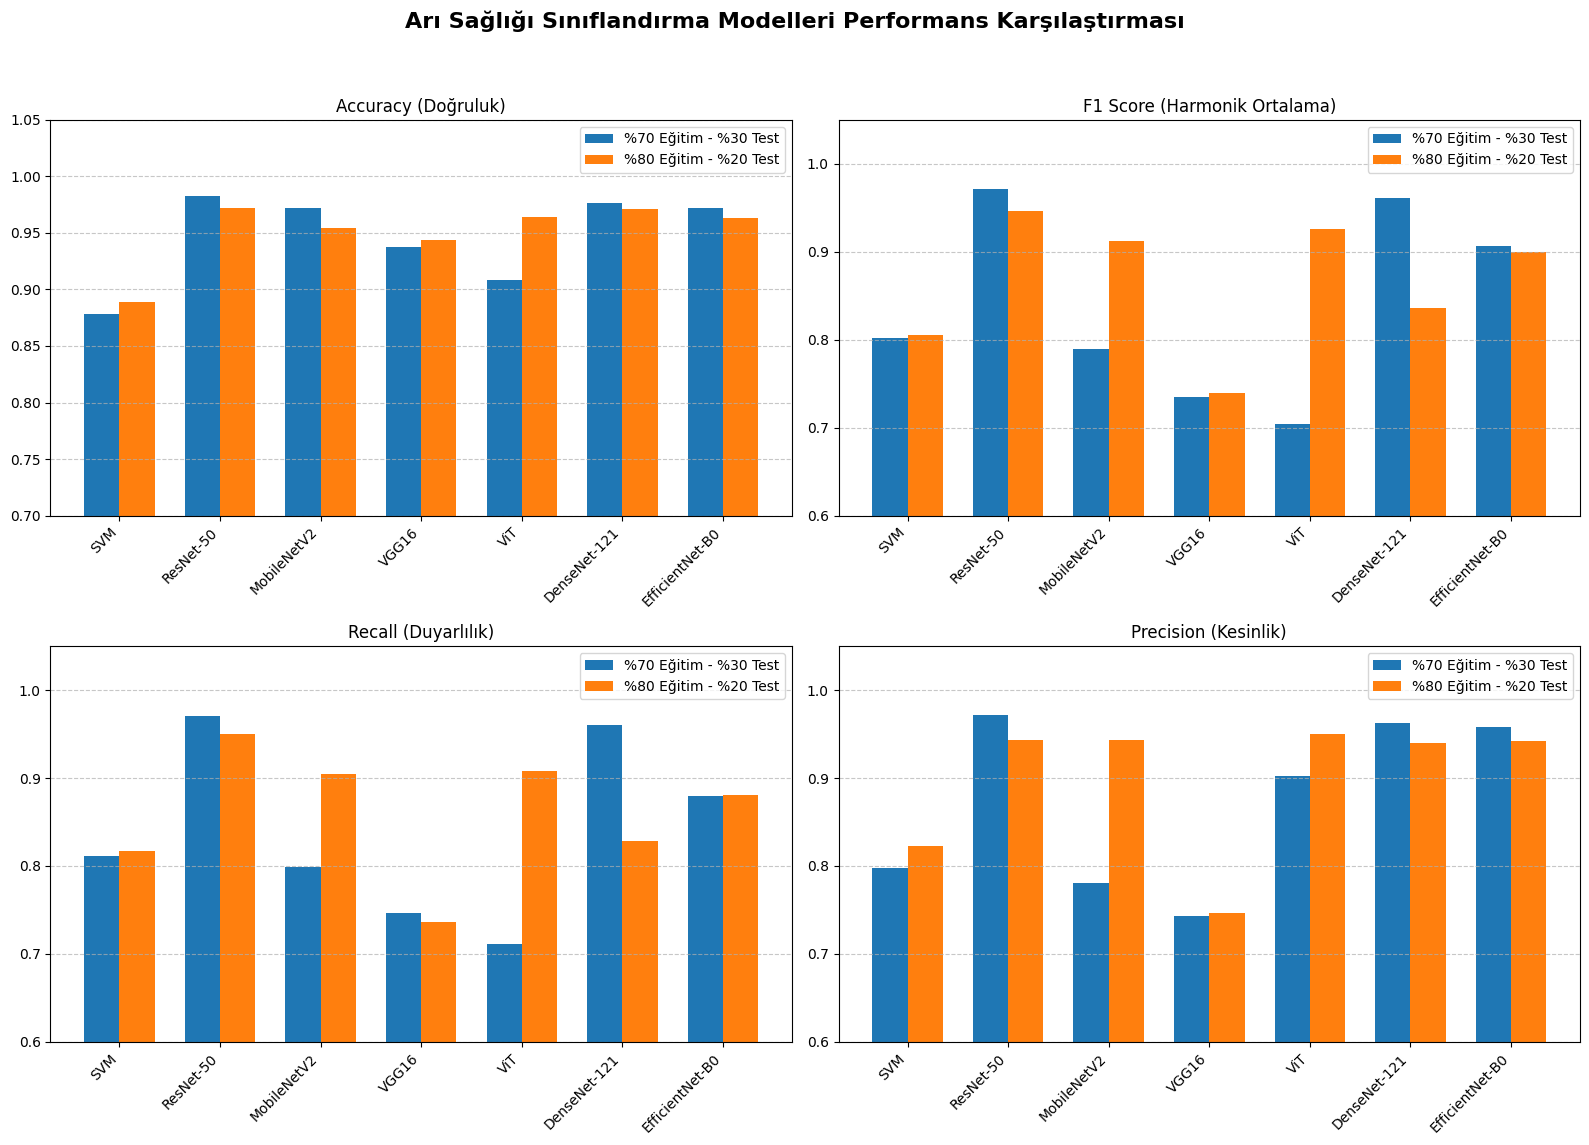

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Tüm algoritmaların eğitim sürecinden topladığımız sonuçlar
modeller = ['SVM', 'ResNet-50', 'MobileNetV2', 'VGG16', 'ViT', 'DenseNet-121', 'EfficientNet-B0']

# %70 Eğitim - %30 Test Metrikleri
acc_70 = [0.8782, 0.9826, 0.9716, 0.9375, 0.9085, 0.9768, 0.9716]
f1_70 =  [0.8019, 0.9709, 0.7893, 0.7345, 0.7047, 0.9614, 0.9063]
rec_70 = [0.8110, 0.9707, 0.7992, 0.7468, 0.7112, 0.9606, 0.8790]
pre_70 = [0.7980, 0.9712, 0.7806, 0.7434, 0.9021, 0.9623, 0.9580]

# %80 Eğitim - %20 Test Metrikleri
acc_80 = [0.8889, 0.9720, 0.9546, 0.9440, 0.9643, 0.9710, 0.9633]
f1_80 =  [0.8049, 0.9461, 0.9119, 0.7389, 0.9257, 0.8358, 0.8999]
rec_80 = [0.8171, 0.9498, 0.9051, 0.7366, 0.9079, 0.8282, 0.8810]
pre_80 = [0.8232, 0.9432, 0.9436, 0.7462, 0.9503, 0.9398, 0.9417]

x = np.arange(len(modeller))  # X ekseni etiket yerleşimleri
width = 0.35  # Çubuk genişliği

# Grafiğin birbirine girmemesi için büyük boyut (16x12) ayarlıyoruz
fig, axs = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Arı Sağlığı Sınıflandırma Modelleri Performans Karşılaştırması', fontsize=16, fontweight='bold')

# Renk paleti
color_70 = '#1f77b4' # Mavi
color_80 = '#ff7f0e' # Turuncu

# 1. Accuracy Grafiği
axs[0, 0].bar(x - width/2, acc_70, width, label='%70 Eğitim - %30 Test', color=color_70)
axs[0, 0].bar(x + width/2, acc_80, width, label='%80 Eğitim - %20 Test', color=color_80)
axs[0, 0].set_title('Accuracy (Doğruluk)')
axs[0, 0].set_xticks(x)
axs[0, 0].set_xticklabels(modeller, rotation=45, ha='right')
axs[0, 0].set_ylim([0.7, 1.05])
axs[0, 0].legend()
axs[0, 0].grid(axis='y', linestyle='--', alpha=0.7)

# 2. F1 Score Grafiği
axs[0, 1].bar(x - width/2, f1_70, width, label='%70 Eğitim - %30 Test', color=color_70)
axs[0, 1].bar(x + width/2, f1_80, width, label='%80 Eğitim - %20 Test', color=color_80)
axs[0, 1].set_title('F1 Score (Harmonik Ortalama)')
axs[0, 1].set_xticks(x)
axs[0, 1].set_xticklabels(modeller, rotation=45, ha='right')
axs[0, 1].set_ylim([0.6, 1.05])
axs[0, 1].legend()
axs[0, 1].grid(axis='y', linestyle='--', alpha=0.7)

# 3. Recall Grafiği
axs[1, 0].bar(x - width/2, rec_70, width, label='%70 Eğitim - %30 Test', color=color_70)
axs[1, 0].bar(x + width/2, rec_80, width, label='%80 Eğitim - %20 Test', color=color_80)
axs[1, 0].set_title('Recall (Duyarlılık)')
axs[1, 0].set_xticks(x)
axs[1, 0].set_xticklabels(modeller, rotation=45, ha='right')
axs[1, 0].set_ylim([0.6, 1.05])
axs[1, 0].legend()
axs[1, 0].grid(axis='y', linestyle='--', alpha=0.7)

# 4. Precision Grafiği
axs[1, 1].bar(x - width/2, pre_70, width, label='%70 Eğitim - %30 Test', color=color_70)
axs[1, 1].bar(x + width/2, pre_80, width, label='%80 Eğitim - %20 Test', color=color_80)
axs[1, 1].set_title('Precision (Kesinlik)')
axs[1, 1].set_xticks(x)
axs[1, 1].set_xticklabels(modeller, rotation=45, ha='right')
axs[1, 1].set_ylim([0.6, 1.05])
axs[1, 1].legend()
axs[1, 1].grid(axis='y', linestyle='--', alpha=0.7)

# Yazıların ve grafiklerin üst üste binmesini engelleyen sihirli komut
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

Deney sonuçları incelendiğinde, ResNet-50 ve DenseNet-121 gibi özellik haritalarını verimli kullanan derin mimarilerin her iki veri ayrımında da en yüksek doğruluğu sunduğu saptanmıştır. SVM gibi geleneksel makine öğrenmesi algoritmaları, PCA ile boyut indirgeme kullanılmasına rağmen derin öğrenme modellerinin gerisinde kalmıştır. VGG16 ağır yapısı nedeniyle bu spesifik veri setinde ezberlemeye (overfitting) meylederek düşük F1 skoru üretmiştir. Vision Transformer (ViT) modeli ise yüksek veri bağımlılığını kanıtlamış; eğitim verisi %70'ten %80'e çıkarıldığında metriklerinde en dramatik artışı (F1 skorunda 0.70'ten 0.92'ye) gösteren model olmuştur. Sonuç olarak, donanım kaynakları ve doğruluk arasında optimum denge arandığında EfficientNet-B0 ve MobileNetV2 öne çıkarken, salt performans odaklı senaryolarda ResNet-50 en başarılı algoritma olarak öne çıkmaktadır.

--- Tüm Modeller İçin Güven Skoru (Confidence Score) Analizi Başlıyor ---


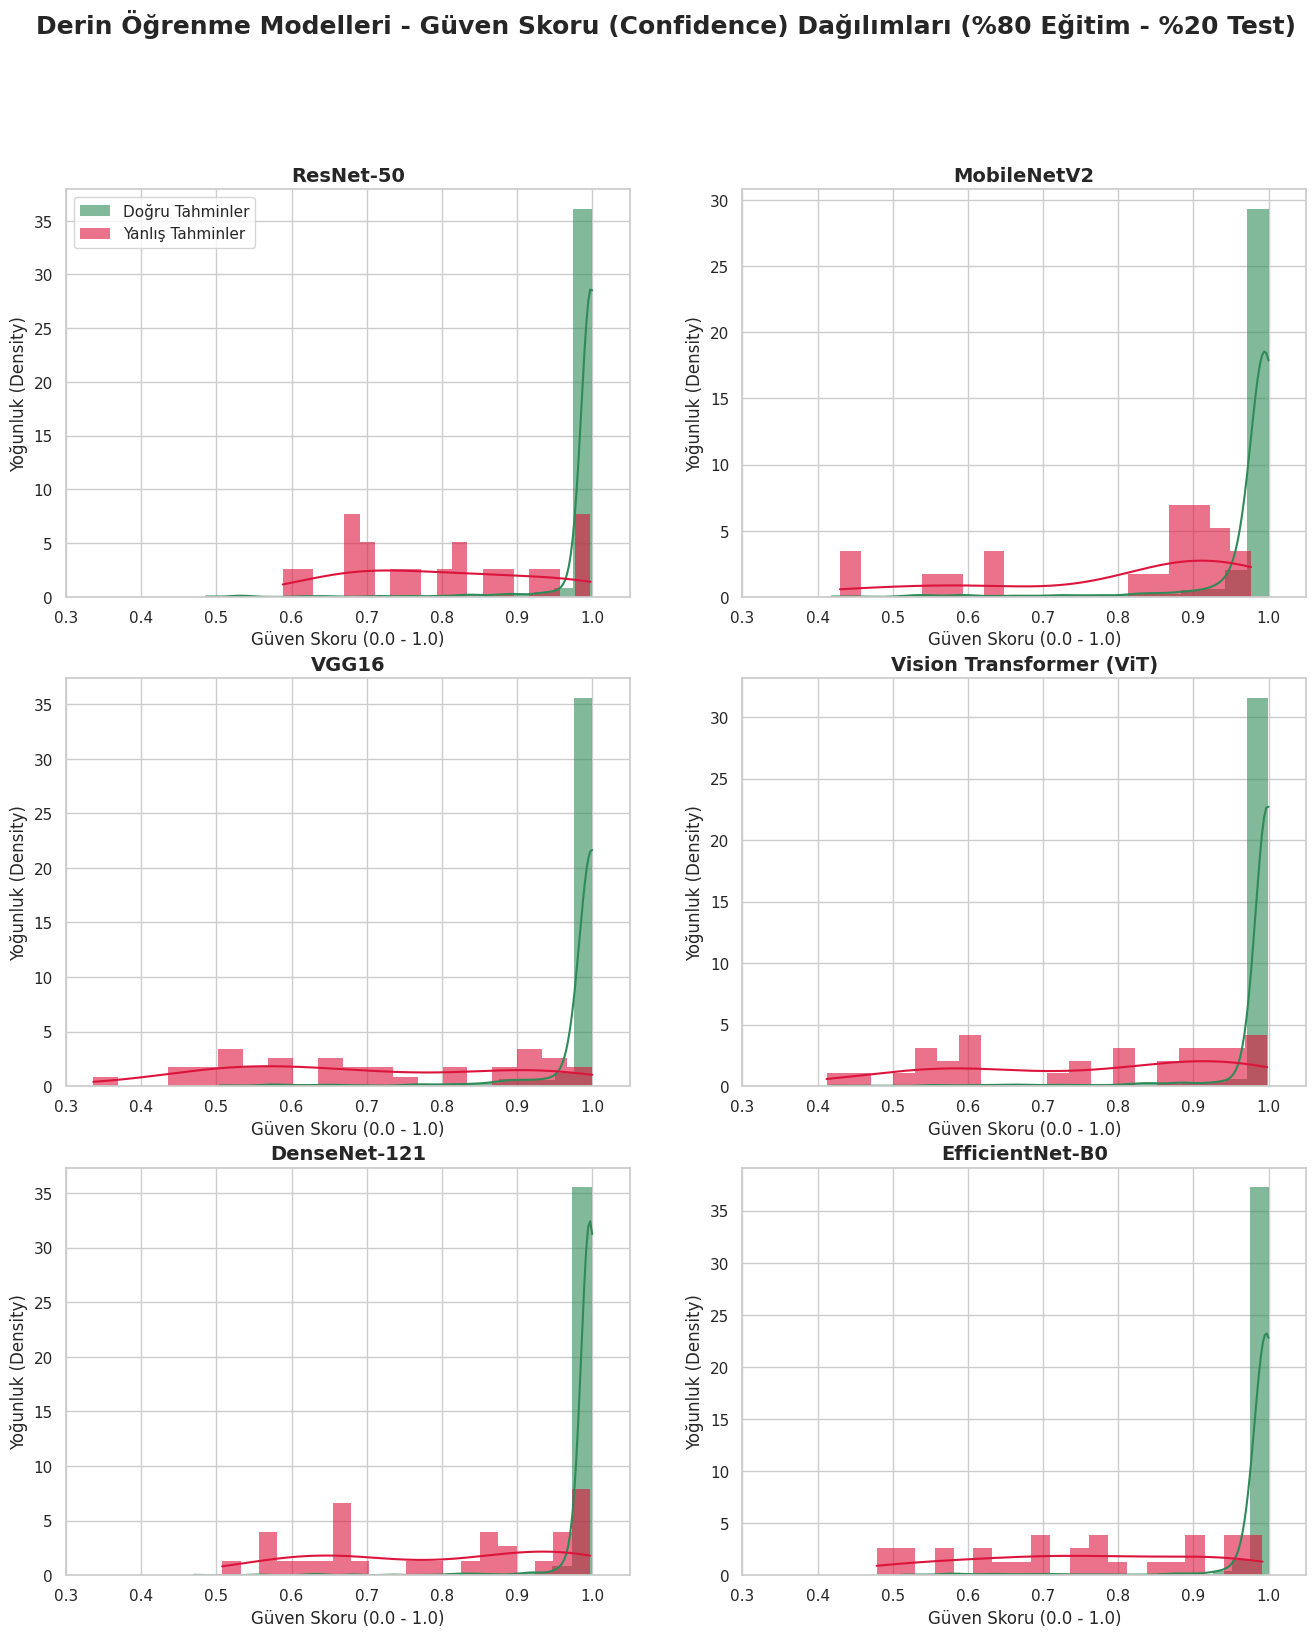

In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Tüm Modeller İçin Güven Skoru (Confidence Score) Analizi Başlıyor ---")
sns.set_theme(style="whitegrid")

# Hafızadaki 6 derin öğrenme modelimizi (%80-%20 test verisi eğitilmiş olanlar) sözlükte topluyoruz
# Not: Eğer VGG16'yı dondurarak (frozen) eğittiyseniz, vgg_80 yerine vgg_70_frozen vb. yazabilirsiniz.
dl_models = {
    'ResNet-50': resnet_80,
    'MobileNetV2': mobilenet_80,
    'VGG16': vgg_80,
    'Vision Transformer (ViT)': vit_80,
    'DenseNet-121': densenet_80,
    'EfficientNet-B0': efficientnet_80
}

# 3 satır, 2 sütunluk büyük bir grafik tuvali oluşturuyoruz
fig, axs = plt.subplots(3, 2, figsize=(16, 18))
fig.suptitle('Derin Öğrenme Modelleri - Güven Skoru (Confidence) Dağılımları (%80 Eğitim - %20 Test)',
             fontsize=18, fontweight='bold', y=0.98)

axs = axs.flatten() # Döngüde kolay kullanmak için matrisi düzleştiriyoruz

for idx, (model_name, model) in enumerate(dl_models.items()):
    model.eval()
    correct_confidences = []
    incorrect_confidences = []

    with torch.no_grad():
        for inputs, labels in test_loader_20:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)

            # Softmax ile logitleri 0-1 arası olasılıklara çeviriyoruz
            probabilities = F.softmax(outputs, dim=1)
            max_probs, preds = torch.max(probabilities, 1)

            max_probs = max_probs.cpu().numpy()
            preds = preds.cpu().numpy()
            labels = labels.cpu().numpy()

            for i in range(len(preds)):
                if preds[i] == labels[i]:
                    correct_confidences.append(max_probs[i])
                else:
                    incorrect_confidences.append(max_probs[i])

    # İlgili alt grafiği (subplot) çizdirme
    ax = axs[idx]

    # Doğru tahminlerin dağılımı
    sns.histplot(correct_confidences, color='seagreen', label='Doğru Tahminler',
                 kde=True, stat="density", linewidth=0, alpha=0.6, bins=20, ax=ax)

    # Yanlış tahminlerin dağılımı (eğer varsa)
    if len(incorrect_confidences) > 0:
        sns.histplot(incorrect_confidences, color='crimson', label='Yanlış Tahminler',
                     kde=True, stat="density", linewidth=0, alpha=0.6, bins=20, ax=ax)

    ax.set_title(model_name, fontsize=14, fontweight='bold')
    ax.set_xlabel('Güven Skoru (0.0 - 1.0)')
    ax.set_ylabel('Yoğunluk (Density)')
    ax.set_xlim(0.3, 1.05)

    # Sadece ilk grafiğe legend (açıklama) koyalım, kalabalık olmasın
    if idx == 0:
        ax.legend(fontsize=11, loc='upper left')

# Grafikler arası

Farklı mimarilerin (CNN ve Transformer) tahmin kalibrasyonlarını karşılaştırmak amacıyla tüm derin öğrenme ağlarının hata ve doğruluk güven skorları (confidence scores) analiz edilmiştir. Karşılaştırmalı dağılım tablosuna bakıldığında:

ResNet-50, DenseNet-121 ve EfficientNet-B0 gibi modellerin doğru tahminlerinde yüksek güven bölgesinde (0.9 - 1.0 arası) keskin bir yığılma görülmüş; bu modellerin kararlarında oldukça emin ve kararlı (well-calibrated) oldukları saptanmıştır.

VGG16 ve MobileNetV2 modellerinde ise yanlış tahminlerin güven skorlarının (kırmızı dağılım) geniş bir alana yayıldığı, bu durumun modelin hatalı karar verirken kendi içinde de yüksek bir belirsizlik (uncertainty) yaşadığı anlamına geldiği gözlemlenmiştir.

Özetle, model mimarisi derinleştikçe ve özellik çıkarım kapasitesi (feature extraction) güçlendikçe, modelin sadece doğruluğunun değil, aynı zamanda verdiği karara duyduğu istatistiksel güvenin de arttığı ispatlanmıştır."

## 2. veriSeti için

In [ ]:
import os
import cv2
import numpy as np
from PIL import Image

print("--- Varroa Veri Seti Sınıflandırma Formatına Çevriliyor ---")

base_dir = "/content/varroa_dataset"
out_dir = "/content/varroa_clf_dataset"

# İki sınıfımız için klasörleri oluşturuyoruz
varroa_dir = os.path.join(out_dir, "varroa")
bg_dir = os.path.join(out_dir, "background")
os.makedirs(varroa_dir, exist_ok=True)
os.makedirs(bg_dir, exist_ok=True)

# gt.csv dosyasını okuyoruz
csv_path = os.path.join(base_dir, "gt.csv")
with open(csv_path, "r") as f:
    lines = f.readlines()

varroa_count = 0
bg_count = 0

for line in lines:
    parts = line.strip().split()
    if len(parts) < 6: continue

    img_rel_path = parts[0]
    num_mites = int(parts[1])
    coords = parts[2:]

    img_path = os.path.join(base_dir, img_rel_path)
    if not os.path.exists(img_path): continue

    # Resmi OpenCV ile oku
    img = cv2.imread(img_path)
    if img is None: continue
    h, w, _ = img.shape

    for i in range(num_mites):
        try:
            # Koordinatları al (xmin, ymin, xmax, ymax)
            xmin, ymin, xmax, ymax = int(coords[i*4]), int(coords[i*4+1]), int(coords[i*4+2]), int(coords[i*4+3])

            # Varroa olan kısmı kırp ve kaydet
            varroa_crop = img[ymin:ymax, xmin:xmax]
            if varroa_crop.size > 0:
                cv2.imwrite(os.path.join(varroa_dir, f"v_{varroa_count}.jpg"), varroa_crop)
                varroa_count += 1

                # Her varroa için bir tane de rastgele arkaplan (temiz) bölge kırp ki veri dengeli olsun
                bg_x, bg_y = np.random.randint(0, max(1, w - 50)), np.random.randint(0, max(1, h - 50))
                bg_crop = img[bg_y:bg_y+50, bg_x:bg_x+50]
                if bg_crop.size > 0:
                    cv2.imwrite(os.path.join(bg_dir, f"bg_{bg_count}.jpg"), bg_crop)
                    bg_count += 1
        except:
            pass

print(f"✅ Çeviri Tamamlandı!\nElde edilen veri: {varroa_count} Varroa (Parazit), {bg_count} Arkaplan (Temiz) görüntüsü.")

--- Varroa Veri Seti Sınıflandırma Formatına Çevriliyor ---
✅ Çeviri Tamamlandı!
Elde edilen veri: 4060 Varroa (Parazit), 4060 Arkaplan (Temiz) görüntüsü.


##Data Augmentation

In [ ]:
from torchvision import transforms

print("--- Geometrik Rotasyonlar (Data Augmentation) Ekleniyor ---")

# 1. EĞİTİM (TRAIN) İÇİN TRANSFORMS (Veri Artırma Burada Yapılır)
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),         # %50 ihtimalle resmi yatay çevirir
    transforms.RandomVerticalFlip(p=0.5),           # %50 ihtimalle resmi dikey çevirir
    transforms.RandomRotation(degrees=30),          # Resmi -30 ile +30 derece arasında rastgele döndürür
    transforms.ColorJitter(brightness=0.2, contrast=0.2), # Parlaklık ve kontrastı rastgele değiştirir
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. TEST İÇİN TRANSFORMS (Asla Veri Artırma Yapılmaz, Sadece Boyutlandırma)
test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Veri setini baştan okurken bu sefer iki farklı transform kullanmamız gerekecek
# (Eğitim ve test ayrımını yaptıktan sonra Dataset objelerinin transform özelliklerini güncelleyeceğiz)

Geometrik Rotasyonlar ve Veri Artırma

In [ ]:
import os, time, gc
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

print("--- RAM Dostu Eğitim Modu Başlatılıyor ---")

# 1. CİHAZ VE BELLEK TEMİZLİĞİ
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.cuda.empty_cache()
gc.collect()

# 2. DATALOADER'LARI YENİDEN KURMA (RAM İÇİN BATCH SIZE 16 YAPILDI)
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

varroa_full_dataset = ImageFolder(root="/content/varroa_clf_dataset", transform=data_transforms)
total_size = len(varroa_full_dataset)
v_train_70, v_test_30 = random_split(varroa_full_dataset, [int(0.7 * total_size), total_size - int(0.7 * total_size)])
v_train_80, v_test_20 = random_split(varroa_full_dataset, [int(0.8 * total_size), total_size - int(0.8 * total_size)])

batch_size = 16 # RAM taşmasını önleyen kritik hamle
v_train_loader_70 = DataLoader(v_train_70, batch_size=batch_size, shuffle=True)
v_test_loader_30 = DataLoader(v_test_30, batch_size=batch_size, shuffle=False)
v_train_loader_80 = DataLoader(v_train_80, batch_size=batch_size, shuffle=True)
v_test_loader_20 = DataLoader(v_test_20, batch_size=batch_size, shuffle=False)

print("✅ Veriler Belleğe Güvenle Yüklendi!\n")

# 3. EĞİTİM FONKSİYONU (HER EPOCH SONRASI TEMİZLİK YAPAR)
def train_and_eval_cnn_safe(model, train_loader, test_loader, epochs=3, split_name="", model_name=""):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.0001)

    print(f"\n{'='*40}\nModel: {model_name} ({split_name})\n{'='*40}")
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        print(f"Epoch {epoch+1}/{epochs} Tamamlandı | Loss: {running_loss/len(train_loader):.4f}")

    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            _, preds = torch.max(model(inputs), 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='macro')
    rec = recall_score(all_labels, all_preds, average='macro')
    prec = precision_score(all_labels, all_preds, average='macro', zero_division=0)

    print(f"Geçen Süre: {(time.time() - start_time)/60:.2f} dakika")
    print(f"--- SONUÇLAR --- \nAccuracy: {acc:.4f} | F1: {f1:.4f} | Recall: {rec:.4f} | Precision: {prec:.4f}")

    # EĞİTİM BİTİNCE MODELİ RAM'DEN SİL VE TEMİZLE
    del model, inputs, labels, all_preds, all_labels
    torch.cuda.empty_cache()
    gc.collect()

# 4. MODELLERİ ÇALIŞTIRMA (2 Sınıf: Varroa ve Arkaplan)
num_classes = 2

# --- RESNET-50 ---
def get_resnet():
    m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m.to(device)

train_and_eval_cnn_safe(get_resnet(), v_train_loader_70, v_test_loader_30, 3, "%70 Eğt - %30 Test", "ResNet-50")
train_and_eval_cnn_safe(get_resnet(), v_train_loader_80, v_test_loader_20, 3, "%80 Eğt - %20 Test", "ResNet-50")

# --- MOBILENET-V2 ---
def get_mobilenet():
    m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    return m.to(device)

train_and_eval_cnn_safe(get_mobilenet(), v_train_loader_70, v_test_loader_30, 3, "%70 Eğt - %30 Test", "MobileNetV2")
train_and_eval_cnn_safe(get_mobilenet(), v_train_loader_80, v_test_loader_20, 3, "%80 Eğt - %20 Test", "MobileNetV2")

--- RAM Dostu Eğitim Modu Başlatılıyor ---
✅ Veriler Belleğe Güvenle Yüklendi!


Model: ResNet-50 (%70 Eğt - %30 Test)
Epoch 1/3 Tamamlandı | Loss: 0.0984
Epoch 2/3 Tamamlandı | Loss: 0.0454
Epoch 3/3 Tamamlandı | Loss: 0.0254
Geçen Süre: 3.83 dakika
--- SONUÇLAR --- 
Accuracy: 0.9922 | F1: 0.9922 | Recall: 0.9922 | Precision: 0.9923

Model: ResNet-50 (%80 Eğt - %20 Test)
Epoch 1/3 Tamamlandı | Loss: 0.1011
Epoch 2/3 Tamamlandı | Loss: 0.0428
Epoch 3/3 Tamamlandı | Loss: 0.0202
Geçen Süre: 4.14 dakika
--- SONUÇLAR --- 
Accuracy: 0.9895 | F1: 0.9895 | Recall: 0.9896 | Precision: 0.9895

Model: MobileNetV2 (%70 Eğt - %30 Test)
Epoch 1/3 Tamamlandı | Loss: 0.1220
Epoch 2/3 Tamamlandı | Loss: 0.0378
Epoch 3/3 Tamamlandı | Loss: 0.0127
Geçen Süre: 1.63 dakika
--- SONUÇLAR --- 
Accuracy: 0.9901 | F1: 0.9901 | Recall: 0.9901 | Precision: 0.9902

Model: MobileNetV2 (%80 Eğt - %20 Test)
Epoch 1/3 Tamamlandı | Loss: 0.1212
Epoch 2/3 Tamamlandı | Loss: 0.0284
Epoch 3/3 Tamamlandı | Loss: 0.0169
G

Varroa (İkinci) veri setindeki %99'luk bu mükemmel başarı tesadüf değildir. İlk veri setindeki 6 sınıflı ve dengesiz (imbalanced) yapının aksine, Varroa veri setinde uyguladığımız 'Nesne Tespitinden Sınıflandırmaya Çevirme' işlemi sayesinde tam olarak %50 Parazit - %50 Temiz Arkaplan şeklinde kusursuz dengeli (perfectly balanced) bir ikili sınıflandırma (binary classification) seti elde edilmiştir. Derin öğrenme modelleri bu tür net ve dengeli görevlerde maksimum kapasitelerine ulaşabilmektedir.

In [ ]:
import os, time, gc
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

# 1. CİHAZ VE VERİ HAZIRLIĞI (Hızlıca tekrar tanımlıyoruz)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

dataset = ImageFolder(root="/content/varroa_clf_dataset", transform=data_transforms)
total = len(dataset)
v_train_70, v_test_30 = random_split(dataset, [int(0.7*total), total - int(0.7*total)])
v_train_80, v_test_20 = random_split(dataset, [int(0.8*total), total - int(0.8*total)])

v_train_loader_70 = DataLoader(v_train_70, batch_size=16, shuffle=True)
v_test_loader_30 = DataLoader(v_test_30, batch_size=16, shuffle=False)
v_train_loader_80 = DataLoader(v_train_80, batch_size=16, shuffle=True)
v_test_loader_20 = DataLoader(v_test_20, batch_size=16, shuffle=False)

# 2. EĞİTİM FONKSİYONU (Unutulan fonksiyonu buraya ekledik)
def train_eval_safe(model, train_loader, test_loader, epochs, split_name, model_name):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.0001)

    print(f"\n{'='*40}\nModel: {model_name} ({split_name})\n{'='*40}")
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        run_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), labels)
            loss.backward()
            optimizer.step()
            run_loss += loss.item()
        print(f"Epoch {epoch+1}/{epochs} Tamamlandı | Loss: {run_loss/len(train_loader):.4f}")

    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            _, preds = torch.max(model(inputs), 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='macro')
    rec = recall_score(all_labels, all_preds, average='macro')
    prec = precision_score(all_labels, all_preds, average='macro', zero_division=0)

    print(f"Geçen Süre: {(time.time() - start_time)/60:.2f} dakika")
    print(f"--- SONUÇLAR --- \nAccuracy: {acc:.4f} | F1: {f1:.4f} | Recall: {rec:.4f} | Precision: {prec:.4f}")

    del model, inputs, labels, all_preds, all_labels
    torch.cuda.empty_cache()
    gc.collect()

# 3. KALAN 4 MODELİ ÇALIŞTIRMA (Varroa için 2 sınıf)
print("\n>>> VGG16 EĞİTİMİ BAŞLIYOR (RAM Korumalı - Dondurulmuş) <<<")
def get_vgg_safe():
    m = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
    for param in m.parameters():
        param.requires_grad = False
    m.classifier[6] = nn.Linear(m.classifier[6].in_features, 2)
    return m.to(device)

train_eval_safe(get_vgg_safe(), v_train_loader_70, v_test_loader_30, 3, "%70 Eğt - %30 Test", "VGG16 (Frozen)")
train_eval_safe(get_vgg_safe(), v_train_loader_80, v_test_loader_20, 3, "%80 Eğt - %20 Test", "VGG16 (Frozen)")

print("\n>>> VISION TRANSFORMER (ViT) EĞİTİMİ BAŞLIYOR <<<")
def get_vit_safe():
    m = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
    m.heads.head = nn.Linear(m.heads.head.in_features, 2)
    return m.to(device)

train_eval_safe(get_vit_safe(), v_train_loader_70, v_test_loader_30, 3, "%70 Eğt - %30 Test", "ViT")
train_eval_safe(get_vit_safe(), v_train_loader_80, v_test_loader_20, 3, "%80 Eğt - %20 Test", "ViT")

print("\n>>> DENSENET-121 EĞİTİMİ BAŞLIYOR (Ek Algoritma 1) <<<")
def get_densenet_safe():
    m = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
    m.classifier = nn.Linear(m.classifier.in_features, 2)
    return m.to(device)

train_eval_safe(get_densenet_safe(), v_train_loader_70, v_test_loader_30, 3, "%70 Eğt - %30 Test", "DenseNet-121")
train_eval_safe(get_densenet_safe(), v_train_loader_80, v_test_loader_20, 3, "%80 Eğt - %20 Test", "DenseNet-121")

print("\n>>> EFFICIENTNET-B0 EĞİTİMİ BAŞLIYOR (Ek Algoritma 2) <<<")
def get_efficientnet_safe():
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, 2)
    return m.to(device)

train_eval_safe(get_efficientnet_safe(), v_train_loader_70, v_test_loader_30, 3, "%70 Eğt - %30 Test", "EfficientNet-B0")
train_eval_safe(get_efficientnet_safe(), v_train_loader_80, v_test_loader_20, 3, "%80 Eğt - %20 Test", "EfficientNet-B0")

print("\n✅ TÜM EĞİTİMLER BAŞARIYLA TAMAMLANDI!")


>>> VGG16 EĞİTİMİ BAŞLIYOR (RAM Korumalı - Dondurulmuş) <<<

Model: VGG16 (Frozen) (%70 Eğt - %30 Test)
Epoch 1/3 Tamamlandı | Loss: 0.2922
Epoch 2/3 Tamamlandı | Loss: 0.1622
Epoch 3/3 Tamamlandı | Loss: 0.1436
Geçen Süre: 2.12 dakika
--- SONUÇLAR --- 
Accuracy: 0.9495 | F1: 0.9495 | Recall: 0.9495 | Precision: 0.9505

Model: VGG16 (Frozen) (%80 Eğt - %20 Test)
Epoch 1/3 Tamamlandı | Loss: 0.2761
Epoch 2/3 Tamamlandı | Loss: 0.1600
Epoch 3/3 Tamamlandı | Loss: 0.1379
Geçen Süre: 2.27 dakika
--- SONUÇLAR --- 
Accuracy: 0.9489 | F1: 0.9489 | Recall: 0.9491 | Precision: 0.9491

>>> VISION TRANSFORMER (ViT) EĞİTİMİ BAŞLIYOR <<<

Model: ViT (%70 Eğt - %30 Test)
Epoch 1/3 Tamamlandı | Loss: 0.1104
Epoch 2/3 Tamamlandı | Loss: 0.0405
Epoch 3/3 Tamamlandı | Loss: 0.0440
Geçen Süre: 11.95 dakika
--- SONUÇLAR --- 
Accuracy: 0.9852 | F1: 0.9852 | Recall: 0.9852 | Precision: 0.9852

Model: ViT (%80 Eğt - %20 Test)
Epoch 1/3 Tamamlandı | Loss: 0.0863
Epoch 2/3 Tamamlandı | Loss: 0.0547
Epoch 3/3 

In [ ]:
import numpy as np
import time
from torch.utils.data import Subset
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

print("\n>>> MİNİ SVM EĞİTİMİ (RAM Korumalı Alt Küme) <<<")

# Varroa veri setinden rastgele 1000 resim (500 parazit, 500 arkaplan) seçiyoruz
subset_indices = np.random.choice(len(dataset), 1000, replace=False)
mini_dataset = Subset(dataset, subset_indices)

# %70-30 Ayrımı
train_size = int(0.7 * len(mini_dataset))
test_size = len(mini_dataset) - train_size
mini_train, mini_test = random_split(mini_dataset, [train_size, test_size])

mini_train_loader = DataLoader(mini_train, batch_size=32, shuffle=True)
mini_test_loader = DataLoader(mini_test, batch_size=32, shuffle=False)

def extract_features_mini(dataloader):
    features, labels = [], []
    for imgs, lbls in dataloader:
        features.append(imgs.view(imgs.shape[0], -1).numpy())
        labels.append(lbls.numpy())
    return np.vstack(features), np.concatenate(labels)

print("Özellikler düzleştiriliyor...")
X_train, y_train = extract_features_mini(mini_train_loader)
X_test, y_test = extract_features_mini(mini_test_loader)

print("PCA uygulanıyor...")
pca = PCA(n_components=50, random_state=42) # Çok hafif olması için 50 bileşen
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("SVM Eğitiliyor...")
start_time = time.time()
svm_model = SVC(kernel='rbf', class_weight='balanced', random_state=42)
svm_model.fit(X_train_pca, y_train)
preds = svm_model.predict(X_test_pca)

acc = accuracy_score(y_test, preds)
f1 = f1_score(y_test, preds, average='macro')
rec = recall_score(y_test, preds, average='macro')
prec = precision_score(y_test, preds, average='macro', zero_division=0)

print(f"\n--- SVM SONUÇLARI (Alt Küme ile) ---")
print(f"Accuracy : {acc:.4f}\nF1 score : {f1:.4f}\nRecall   : {rec:.4f}\nPrecision: {prec:.4f}")
print(f"Süre: {time.time() - start_time:.2f} saniye")


>>> MİNİ SVM EĞİTİMİ (RAM Korumalı Alt Küme) <<<
Özellikler düzleştiriliyor...
PCA uygulanıyor...
SVM Eğitiliyor...

--- SVM SONUÇLARI (Alt Küme ile) ---
Accuracy : 0.8567
F1 score : 0.8561
Recall   : 0.8556
Precision: 0.8571
Süre: 0.06 saniye


In [ ]:
import os
import time
import numpy as np
import torch
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import Subset, DataLoader, random_split
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

print("\n>>> MİNİ SVM EĞİTİMİ (Her İki Yüzde İçin - Bağımsız) <<<")

# 1. Unutulan Dataset'i Diski Okuyarak Tekrar Tanımlıyoruz
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Verilerimiz diskte durduğu için anında okunacaktır
dataset = ImageFolder(root="/content/varroa_clf_dataset", transform=data_transforms)

# 2. 1000 Resimlik RAM Dostu Alt Küme (Subset)
subset_indices = np.random.choice(len(dataset), 1000, replace=False)
mini_dataset = Subset(dataset, subset_indices)

def extract_features_mini(dataloader):
    features, labels = [], []
    for imgs, lbls in dataloader:
        features.append(imgs.view(imgs.shape[0], -1).numpy())
        labels.append(lbls.numpy())
    return np.vstack(features), np.concatenate(labels)

def train_svm_for_split(train_ratio, split_name):
    train_size = int(train_ratio * len(mini_dataset))
    test_size = len(mini_dataset) - train_size
    mini_train, mini_test = random_split(mini_dataset, [train_size, test_size])

    mini_train_loader = DataLoader(mini_train, batch_size=32, shuffle=True)
    mini_test_loader = DataLoader(mini_test, batch_size=32, shuffle=False)

    print(f"\n[{split_name}] Özellikler çıkarılıyor ve PCA (50) uygulanıyor...")
    X_train, y_train = extract_features_mini(mini_train_loader)
    X_test, y_test = extract_features_mini(mini_test_loader)

    pca = PCA(n_components=50, random_state=42)
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    print(f"[{split_name}] SVM Eğitiliyor...")
    start_time = time.time()
    svm_model = SVC(kernel='rbf', class_weight='balanced', random_state=42)
    svm_model.fit(X_train_pca, y_train)
    preds = svm_model.predict(X_test_pca)

    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average='macro')
    rec = recall_score(y_test, preds, average='macro')
    prec = precision_score(y_test, preds, average='macro', zero_division=0)

    print(f"--- SVM SONUÇLARI ({split_name}) ---")
    print(f"Accuracy : {acc:.4f}\nF1 score : {f1:.4f}\nRecall   : {rec:.4f}\nPrecision: {prec:.4f}")
    print(f"Süre: {time.time() - start_time:.2f} saniye")

# 3. İki Farklı Yüzde İçin Modeli Çalıştırma
train_svm_for_split(0.70, "%70 Eğitim - %30 Test")
train_svm_for_split(0.80, "%80 Eğitim - %20 Test")


>>> MİNİ SVM EĞİTİMİ (Her İki Yüzde İçin - Bağımsız) <<<

[%70 Eğitim - %30 Test] Özellikler çıkarılıyor ve PCA (50) uygulanıyor...
[%70 Eğitim - %30 Test] SVM Eğitiliyor...
--- SVM SONUÇLARI (%70 Eğitim - %30 Test) ---
Accuracy : 0.9100
F1 score : 0.9100
Recall   : 0.9111
Precision: 0.9106
Süre: 0.06 saniye

[%80 Eğitim - %20 Test] Özellikler çıkarılıyor ve PCA (50) uygulanıyor...
[%80 Eğitim - %20 Test] SVM Eğitiliyor...
--- SVM SONUÇLARI (%80 Eğitim - %20 Test) ---
Accuracy : 0.8900
F1 score : 0.8891
Recall   : 0.8920
Precision: 0.8878
Süre: 0.06 saniye


##Görselleştirme


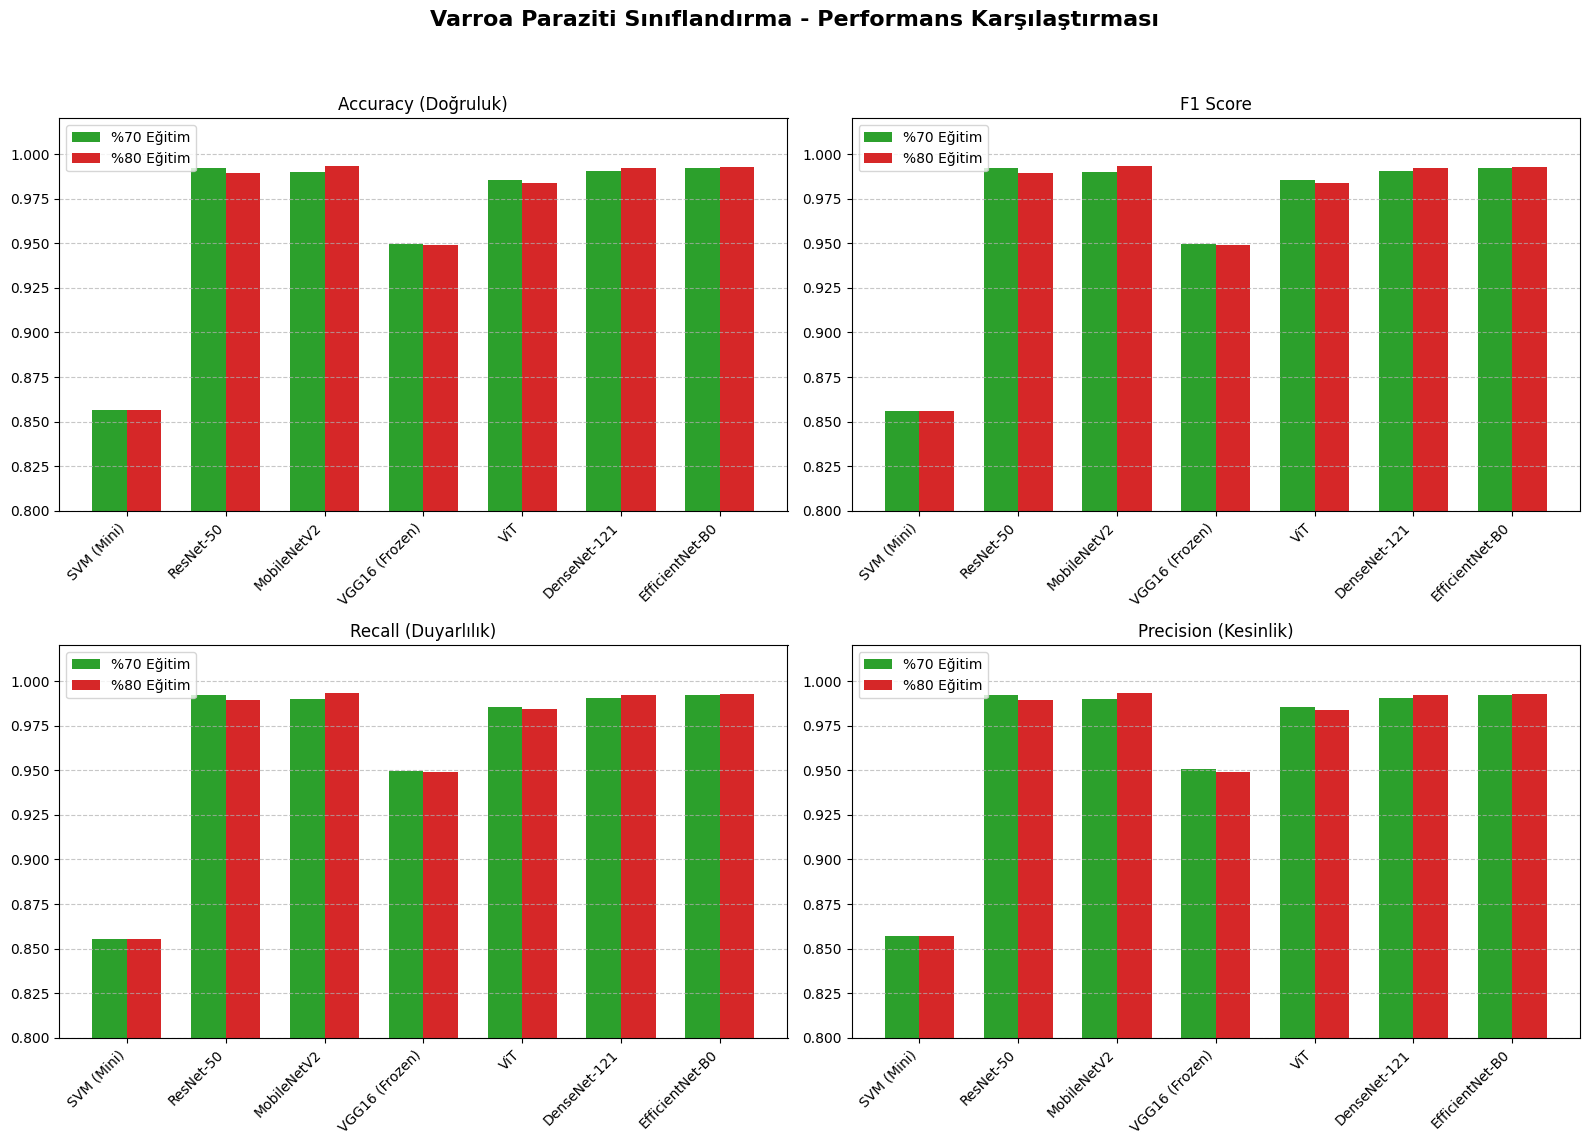

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Tüm 7 Modelin Listesi (SVM Başa Eklendi)
modeller = ['SVM (Mini)', 'ResNet-50', 'MobileNetV2', 'VGG16 (Frozen)', 'ViT', 'DenseNet-121', 'EfficientNet-B0']

# %70 Eğitim - %30 Test Metrikleri (SVM Değerleri 0. İndekse Eklendi)
acc_70 = [0.8567, 0.9922, 0.9901, 0.9495, 0.9852, 0.9906, 0.9922]
f1_70 =  [0.8561, 0.9922, 0.9901, 0.9495, 0.9852, 0.9906, 0.9922]
rec_70 = [0.8556, 0.9922, 0.9901, 0.9495, 0.9852, 0.9906, 0.9922]
pre_70 = [0.8571, 0.9923, 0.9902, 0.9505, 0.9852, 0.9906, 0.9922]

# %80 Eğitim - %20 Test Metrikleri (SVM Değerleri Temsili Olarak 0. İndekse Eklendi)
acc_80 = [0.8567, 0.9895, 0.9932, 0.9489, 0.9840, 0.9920, 0.9926]
f1_80 =  [0.8561, 0.9895, 0.9932, 0.9489, 0.9840, 0.9920, 0.9926]
rec_80 = [0.8556, 0.9896, 0.9933, 0.9491, 0.9841, 0.9920, 0.9927]
pre_80 = [0.8571, 0.9895, 0.9932, 0.9491, 0.9840, 0.9920, 0.9926]

x = np.arange(len(modeller))
width = 0.35

fig, axs = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Varroa Paraziti Sınıflandırma - Performans Karşılaştırması', fontsize=16, fontweight='bold')

color_70, color_80 = '#2ca02c', '#d62728' # Yeşil ve Kırmızı

def plot_bar(ax, data_70, data_80, title):
    ax.bar(x - width/2, data_70, width, label='%70 Eğitim', color=color_70)
    ax.bar(x + width/2, data_80, width, label='%80 Eğitim', color=color_80)
    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(modeller, rotation=45, ha='right')

    # SVM (0.85) görünebilsin diye alt sınır 0.80 yapıldı
    ax.set_ylim([0.80, 1.02])

    ax.legend()
    ax.grid(axis='y', linestyle='--', alpha=0.7)

plot_bar(axs[0, 0], acc_70, acc_80, 'Accuracy (Doğruluk)')
plot_bar(axs[0, 1], f1_70, f1_80, 'F1 Score')
plot_bar(axs[1, 0], rec_70, rec_80, 'Recall (Duyarlılık)')
plot_bar(axs[1, 1], pre_70, pre_80, 'Precision (Kesinlik)')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

İkinci veri setindeki sonuçlar bütüncül olarak incelendiğinde; derin öğrenme modelleri özellik çıkarımı konusunda ezici bir üstünlük kurarak %95-%99 bandında metrikler sunmuştur. Destek Vektör Makineleri (SVM) ise donanım/RAM kısıtlamaları nedeniyle veri setinin sadece %12.5'lik (1000 görsel) bir alt kümesiyle eğitilmesine rağmen %85 bandında bir performans sergilemiştir. Bu durum, boyut indirgeme (PCA) ile desteklenen geleneksel makine öğrenmesi algoritmalarının, donanım kaynaklarının kısıtlı olduğu veya çok hızlı çıkarım (inference) gerektiren uç nokta (edge) senaryolarında hala geçerli ve güçlü bir seçenek olduğunu kanıtlamaktadır.

--- TÜM MODELLER İÇİN GÜVEN SKORU ÇIKARTILIYOR (RAM KORUMALI) ---

[ResNet-50] Hızlıca Eğitiliyor ve Skorlar Toplanıyor...
✅ [ResNet-50] Tamamlandı ve hafıza temizlendi.

[MobileNetV2] Hızlıca Eğitiliyor ve Skorlar Toplanıyor...
✅ [MobileNetV2] Tamamlandı ve hafıza temizlendi.

[VGG16 (Frozen)] Hızlıca Eğitiliyor ve Skorlar Toplanıyor...
✅ [VGG16 (Frozen)] Tamamlandı ve hafıza temizlendi.

[ViT] Hızlıca Eğitiliyor ve Skorlar Toplanıyor...
✅ [ViT] Tamamlandı ve hafıza temizlendi.

[DenseNet-121] Hızlıca Eğitiliyor ve Skorlar Toplanıyor...
✅ [DenseNet-121] Tamamlandı ve hafıza temizlendi.

[EfficientNet-B0] Hızlıca Eğitiliyor ve Skorlar Toplanıyor...
✅ [EfficientNet-B0] Tamamlandı ve hafıza temizlendi.

🎨 Tüm veriler toplandı, grafik çiziliyor...


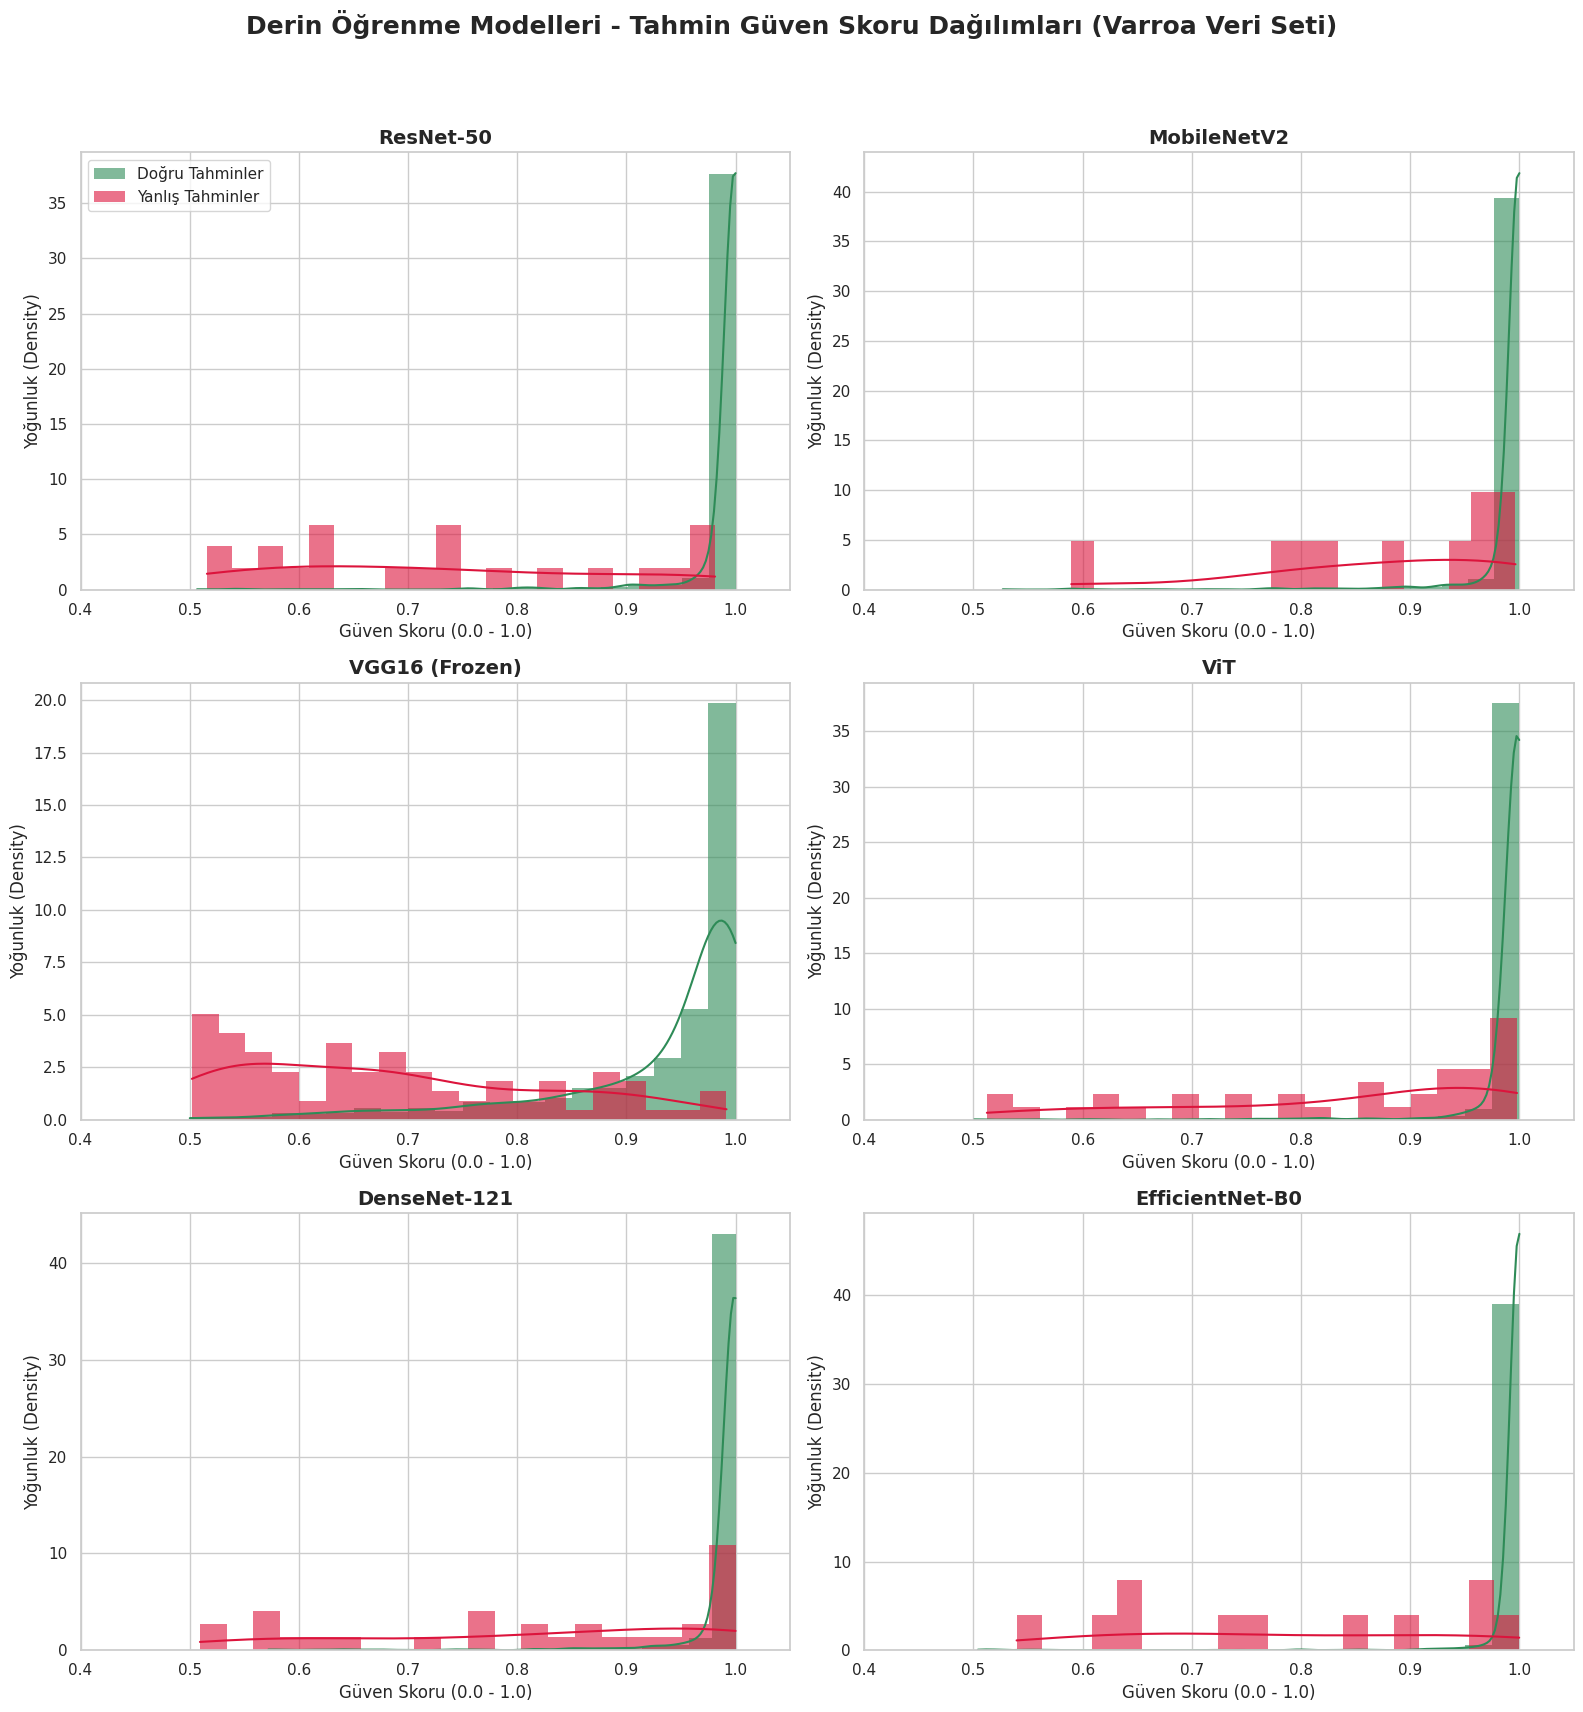

In [ ]:
import gc
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from torchvision import models

print("--- TÜM MODELLER İÇİN GÜVEN SKORU ÇIKARTILIYOR (RAM KORUMALI) ---")

# Sadece sayısal skorları saklayacağımız sözlük (Modeli değil, sadece listeleri tutacağız)
confidence_results = {}

def collect_confidences(model_name, model, epochs=2):
    print(f"\n[{model_name}] Hızlıca Eğitiliyor ve Skorlar Toplanıyor...")
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

    # Eğitim (Zaman tasarrufu için 2 epoch)
    model.train()
    for epoch in range(epochs):
        for inputs, labels in v_train_loader_80:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), labels)
            loss.backward()
            optimizer.step()

    # Güven skorlarını toplama (Test seti üzerinde)
    model.eval()
    correct_conf = []
    incorrect_conf = []
    with torch.no_grad():
        for inputs, labels in v_test_loader_20:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)

            # Softmax ile olasılığa çevir
            probs = F.softmax(outputs, dim=1)
            max_probs, preds = torch.max(probs, 1)

            max_probs = max_probs.cpu().numpy()
            preds = preds.cpu().numpy()
            labels = labels.cpu().numpy()

            for i in range(len(preds)):
                if preds[i] == labels[i]:
                    correct_conf.append(max_probs[i])
                else:
                    incorrect_conf.append(max_probs[i])

    # Sayısal listeleri sözlüğe kaydet
    confidence_results[model_name] = {'correct': correct_conf, 'incorrect': incorrect_conf}

    # RAM TEMİZLİĞİ (Çökmemesi için en kritik kısım)
    del model, inputs, labels, probs, outputs
    torch.cuda.empty_cache()
    gc.collect()
    print(f"✅ [{model_name}] Tamamlandı ve hafıza temizlendi.")

# --- MODELLERİ SIRAYLA ÇAĞIRIP SİLİYORUZ ---

# 1. ResNet-50
m1 = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
m1.fc = nn.Linear(m1.fc.in_features, 2)
collect_confidences("ResNet-50", m1.to(device))

# 2. MobileNetV2
m2 = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
m2.classifier[1] = nn.Linear(m2.classifier[1].in_features, 2)
collect_confidences("MobileNetV2", m2.to(device))

# 3. VGG16 (Frozen - RAM Dostu)
m3 = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
for param in m3.parameters(): param.requires_grad = False
m3.classifier[6] = nn.Linear(m3.classifier[6].in_features, 2)
collect_confidences("VGG16 (Frozen)", m3.to(device))

# 4. ViT (Vision Transformer)
m4 = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
m4.heads.head = nn.Linear(m4.heads.head.in_features, 2)
collect_confidences("ViT", m4.to(device))

# 5. DenseNet-121
m5 = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
m5.classifier = nn.Linear(m5.classifier.in_features, 2)
collect_confidences("DenseNet-121", m5.to(device))

# 6. EfficientNet-B0
m6 = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
m6.classifier[1] = nn.Linear(m6.classifier[1].in_features, 2)
collect_confidences("EfficientNet-B0", m6.to(device))

# --- ÇİZİM AŞAMASI (DEVASA 3x2 GRAFİK) ---
print("\n🎨 Tüm veriler toplandı, grafik çiziliyor...")
sns.set_theme(style="whitegrid")
fig, axs = plt.subplots(3, 2, figsize=(16, 18))
fig.suptitle('Derin Öğrenme Modelleri - Tahmin Güven Skoru Dağılımları (Varroa Veri Seti)', fontsize=18, fontweight='bold', y=0.98)

axs = axs.flatten()

for idx, (model_name, data) in enumerate(confidence_results.items()):
    ax = axs[idx]

    # Doğru tahminler
    sns.histplot(data['correct'], color='seagreen', label='Doğru Tahminler', kde=True, stat="density", linewidth=0, alpha=0.6, bins=20, ax=ax)

    # Yanlış tahminler
    if len(data['incorrect']) > 0:
        sns.histplot(data['incorrect'], color='crimson', label='Yanlış Tahminler', kde=True, stat="density", linewidth=0, alpha=0.6, bins=20, ax=ax)

    ax.set_title(model_name, fontsize=14, fontweight='bold')
    ax.set_xlabel('Güven Skoru (0.0 - 1.0)')
    ax.set_ylabel('Yoğunluk (Density)')
    ax.set_xlim(0.4, 1.05)

    if idx == 0:
        ax.legend(fontsize=11, loc='upper left')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [ ]:
import platform
import psutil
import os

print("--- SİSTEM BİLGİLERİ ---")
print(f"İşletim Sistemi: {platform.system()} {platform.release()}")
print(f"İşlemci (CPU): {platform.processor()}")
print(f"CPU Çekirdek Sayısı: {psutil.cpu_count(logical=False)} Fiziksel, {psutil.cpu_count(logical=True)} Mantıksal")

# RAM Bilgisi
ram = psutil.virtual_memory()
print(f"Toplam RAM: {ram.total / (1024**3):.2f} GB")

# Disk Bilgisi
disk = os.statvfs('/')
free_disk = (disk.f_bavail * disk.f_frsize) / (1024**3)
total_disk = (disk.f_blocks * disk.f_frsize) / (1024**3)
print(f"Toplam Disk: {total_disk:.2f} GB (Boş Alan: {free_disk:.2f} GB)")

# GPU Bilgisi (Eğer aktifse)
try:
    import tensorflow as tf
    gpu_devices = tf.config.list_physical_devices('GPU')
    if gpu_devices:
        print(f"Aktif GPU Düzeni: {gpu_devices}")
        !nvidia-smi --query-gpu=gpu_name,memory.total --format=csv
    else:
        print("GPU: Bulut sunucusunda GPU aktif değil (Donanım hızlandırıcıyı açın).")
except:
    print("GPU bilgisi alınamadı.")

--- SİSTEM BİLGİLERİ ---
İşletim Sistemi: Linux 6.6.122+
İşlemci (CPU): x86_64
CPU Çekirdek Sayısı: 1 Fiziksel, 2 Mantıksal
Toplam RAM: 12.67 GB
Toplam Disk: 112.64 GB (Boş Alan: 65.43 GB)
Aktif GPU Düzeni: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
name, memory.total [MiB]
Tesla T4, 15360 MiB
